# Аналитический отчёт по сетке экспериментов RAG-Scope-RU
Ноутбук спроектирован под полномасштабную сетку из **12+ моделей эмбеддингов**, **4 размеров чанков** (`256`, `512`, `1024`, `2048`) и **3 стратегий извлечения** (`Dense`, `Hybrid`, `Hybrid + Rerank`).

## 1. Загрузка и структурирование пространства гиперпараметров

In [30]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams["figure.dpi"] = 130
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["grid.linestyle"] = "--"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP_DIR = ROOT / "experiments"

MODEL_GROUPS = {
    "multilingual-e5-small": "Семейство E5 (Multilingual)",
    "multilingual-e5-base": "Семейство E5 (Multilingual)",
    "multilingual-e5-large": "Семейство E5 (Multilingual)",
    "bge-m3": "Длинноконтекстные SOTA",
    "gte-multilingual-base": "Длинноконтекстные SOTA",
    "USER-bge-m3": "RU-адаптированные",
    "USER-base": "RU-адаптированные",
    "ru-en-RoSBERTa": "RU-адаптированные",
    "sbert_large_nlu_ru": "RU-адаптированные",
    "rubert-tiny2": "Легковесные / Baseline",
    "LaBSE-en-ru": "Легковесные / Baseline",
    "paraphrase-multilingual-mpnet-base-v2": "Легковесные / Baseline",
    "all-MiniLM-L6-v2": "Легковесные / Baseline",
}

rows = []
per_question_rows = []

for path in sorted(EXP_DIR.glob("*/metrics_*.json")):
    data = json.loads(path.read_text(encoding="utf-8"))
    cfg_ing = data.get("config", {}).get("ingest", {})
    cfg_ret = data.get("config", {}).get("retrieve", {})
    summary = data.get("summary", {})
    hits = summary.get("hit_rate", {})

    use_hybrid = cfg_ret.get("use_hybrid", False)
    use_rerank = cfg_ret.get("use_rerank", False)
    if use_hybrid and use_rerank:
        strategy = "Hybrid + Rerank"
    elif use_hybrid:
        strategy = "Hybrid"
    else:
        strategy = "Dense"

    full_model = cfg_ing.get("embedding_model", "—")
    short_model = full_model.split("/")[-1]
    chunk_size = cfg_ing.get("chunk_size", 512)
    chunk_strategy = cfg_ing.get("chunk_strategy", "structural")
    tag = data.get("tag", path.stem)

    rows.append({
        "tag": tag,
        "group": MODEL_GROUPS.get(short_model, "Прочие"),
        "embedding": short_model,
        "strategy": strategy,
        "chunk_strategy": chunk_strategy,
        "chunk_size": int(chunk_size),
        "overlap": int(cfg_ing.get("chunk_overlap", 64)),
        "hit@1": hits.get("@1", np.nan),
        "hit@3": hits.get("@3", np.nan),
        "hit@5": hits.get("@5", np.nan),
        "hit@10": hits.get("@10", np.nan),
        "mrr": summary.get("mrr", np.nan),
        "ms_per_query": summary.get("ms_per_query", np.nan),
        "timestamp": data.get("timestamp", ""),
    })

    for pq in data.get("per_question", []):
        per_question_rows.append({
            "tag": tag,
            "embedding": short_model,
            "strategy": strategy,
            "chunk_size": int(chunk_size),
            "question_id": pq["id"],
            "target": pq["target"],
            "hit@1": pq.get("hit@1", 0.0),
            "hit@5": pq.get("hit@5", 0.0),
            "rr": pq.get("rr", 0.0),
        })

df = pd.DataFrame(rows).sort_values("mrr", ascending=False).reset_index(drop=True)
df_pq = pd.DataFrame(per_question_rows)

print(f"Загружено прогонов: {len(df)} | Уникальных моделей: {df['embedding'].nunique()}")
df.head(15)

Загружено прогонов: 57 | Уникальных моделей: 7


,tag,group,embedding,strategy,chunk_strategy,chunk_size,overlap,hit@1,hit@3,hit@5,hit@10,mrr,ms_per_query,timestamp
0,e5_small_c1024_hybrid_rerank,Семейство E5 (Multilingual),multilingual-e5-small,Hybrid + Rerank,structural,1024,128,0.880,0.930,0.950,0.960,0.907806,1181.501074,20261027_194853
1,e5_large_c256_hybrid_rerank,Семейство E5 (Multilingual),multilingual-e5-large,Hybrid + Rerank,structural,256,32,0.865,0.935,0.955,0.980,0.903190,438.218815,20261027_230940
2,e5_large_c1024_hybrid_rerank,Семейство E5 (Multilingual),multilingual-e5-large,Hybrid + Rerank,structural,1024,128,0.865,0.925,0.945,0.970,0.900887,1209.776217,20261027_222640
3,sbert_large_c1024_hybrid_rerank,RU-адаптированные,sbert_large_nlu_ru,Hybrid + Rerank,structural,1024,128,0.865,0.920,0.930,0.950,0.894333,1138.800331,20261027_215351
4,e5_small_c512_hybrid_rerank,Семейство E5 (Multilingual),multilingual-e5-small,Hybrid + Rerank,structural,512,64,0.855,0.930,0.935,0.955,0.891131,670.757056,20261027_202227
5,e5_base_c1024_hybrid_rerank,Семейство E5 (Multilingual),multilingual-e5-base,Hybrid + Rerank,structural,1024,128,0.855,0.930,0.940,0.950,0.890500,1185.223026,20261027_204853
6,rubert_tiny2_c1024_hybrid_rerank,Легковесные / Baseline,rubert-tiny2,Hybrid + Rerank,structural,1024,128,0.855,0.915,0.940,0.960,0.889984,1098.980683,20261027_225328
7,e5_large_c256_hybrid,Семейство E5 (Multilingual),multilingual-e5-large,Hybrid,structural,256,32,0.845,0.915,0.955,0.970,0.889458,30.524371,20261027_230745
8,e5_small_c256_hybrid_rerank,Семейство E5 (Multilingual),multilingual-e5-small,Hybrid + Rerank,structural,256,32,0.845,0.930,0.940,0.965,0.887768,405.365155,20261027_200624
9,rubert_tiny2_c512_hybrid_rerank,Легковесные / Baseline,rubert-tiny2,Hybrid + Rerank,structural,512,64,0.845,0.930,0.935,0.950,0.886353,627.340308,20261027_232217


## 2. Лидерборд моделей (Лучшая конфигурация для каждой модели)
Когда в сетке 100+ запусков, сводная таблица агрегирует **лучший результат каждой модели** с указанием того, на каком размере чанка и какой стратегии он был достигнут.

In [31]:
best_per_model = (
    df.sort_values("mrr", ascending=False)
    .groupby("embedding", as_index=False)
    .first()
    .sort_values("mrr", ascending=False)
    .reset_index(drop=True)
)
best_per_model.index = best_per_model.index + 1

cols_order = [
    "group", "embedding", "strategy", "chunk_size",
    "hit@1", "hit@3", "hit@5", "hit@10", "mrr", "ms_per_query"
]
metric_cols = ["hit@1", "hit@3", "hit@5", "hit@10", "mrr"]

try:
    styled_best = (
        best_per_model[cols_order]
        .style.format({
            "hit@1": "{:.3f}",
            "hit@3": "{:.3f}",
            "hit@5": "{:.3f}",
            "hit@10": "{:.3f}",
            "mrr": "{:.3f}",
            "ms_per_query": "{:.1f} мс",
        }, na_rep="—")
        .background_gradient(subset=metric_cols, cmap="YlGn")
        .background_gradient(subset=["ms_per_query"], cmap="YlOrRd")
    )
    display(styled_best)
except ImportError:
    display(best_per_model[cols_order].round(3))

,group,embedding,strategy,chunk_size,hit@1,hit@3,hit@5,hit@10,mrr,ms_per_query
1,Семейство E5 (Multilingual),multilingual-e5-small,Hybrid + Rerank,1024,0.880,0.930,0.950,0.960,0.908,1181.5 мс
2,Семейство E5 (Multilingual),multilingual-e5-large,Hybrid + Rerank,256,0.865,0.935,0.955,0.980,0.903,438.2 мс
3,RU-адаптированные,sbert_large_nlu_ru,Hybrid + Rerank,1024,0.865,0.920,0.930,0.950,0.894,1138.8 мс
4,Семейство E5 (Multilingual),multilingual-e5-base,Hybrid + Rerank,1024,0.855,0.930,0.940,0.950,0.891,1185.2 мс
5,Легковесные / Baseline,rubert-tiny2,Hybrid + Rerank,1024,0.855,0.915,0.940,0.960,0.890,1099.0 мс
6,Легковесные / Baseline,paraphrase-multilingual-mpnet-base-v2,Hybrid + Rerank,256,0.850,0.915,0.930,0.955,0.885,410.7 мс
7,Легковесные / Baseline,LaBSE-en-ru,Hybrid + Rerank,512,0.840,0.915,0.925,0.950,0.879,658.2 мс


## 3. Полная тепловая матрица сетки: Модель × (Размер чанка + Стратегия)
Позволяет охватить взглядом все 100+ экспериментов одновременно (формат бенчмарка MTEB).

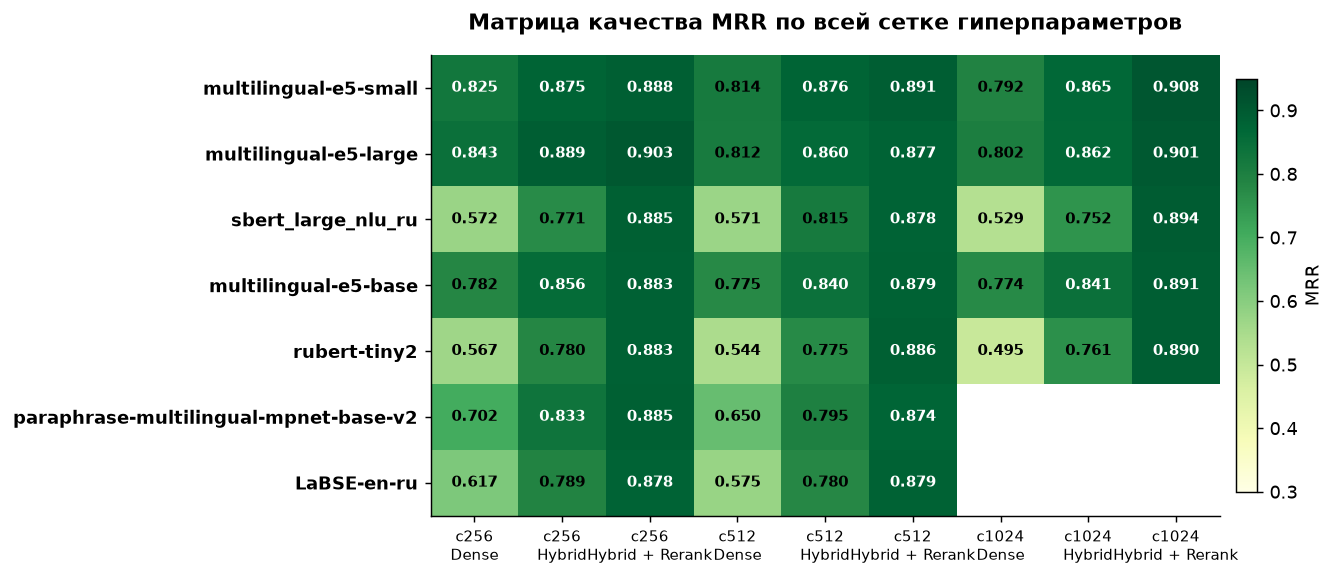

In [32]:
df_struct = df[df["chunk_strategy"] == "structural"].copy()
if df_struct.empty:
    df_struct = df.copy()

df_struct["col_key"] = "c" + df_struct["chunk_size"].astype(str) + "\n" + df_struct["strategy"]

strat_order = {"Dense": 0, "Hybrid": 1, "Hybrid + Rerank": 2}
col_order = (
    df_struct[["chunk_size", "strategy", "col_key"]]
    .drop_duplicates()
    .assign(s_ord=lambda x: x["strategy"].map(strat_order))
    .sort_values(["chunk_size", "s_ord"])["col_key"]
    .tolist()
)

model_order = best_per_model["embedding"].tolist()
pivot_grid = df_struct.pivot_table(
    index="embedding", columns="col_key", values="mrr", aggfunc="max"
).reindex(index=model_order, columns=col_order)

fig_w = max(10, len(pivot_grid.columns) * 1.15)
fig_h = max(4.5, len(pivot_grid.index) * 0.65)
fig, ax = plt.subplots(figsize=(fig_w, fig_h))

im = ax.imshow(pivot_grid.values, cmap="YlGn", aspect="auto", vmin=0.3, vmax=0.95)
ax.set_xticks(range(len(pivot_grid.columns)))
ax.set_xticklabels(pivot_grid.columns, fontsize=8.5)
ax.set_yticks(range(len(pivot_grid.index)))
ax.set_yticklabels(pivot_grid.index, fontweight="bold")
ax.set_title("Матрица качества MRR по всей сетке гиперпараметров", fontsize=12, fontweight="bold", pad=14)
ax.grid(False)

for i in range(len(pivot_grid.index)):
    for j in range(len(pivot_grid.columns)):
        val = pivot_grid.values[i, j]
        if not np.isnan(val):
            text_color = "white" if val > 0.82 else "black"
            ax.text(j, i, f"{val:.3f}", ha="center", va="center", color=text_color, fontsize=8.5, fontweight="bold")

plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="MRR")
plt.tight_layout()
plt.show()

## 4. Влияние стратегии поиска и размера чанка в разрезе моделей

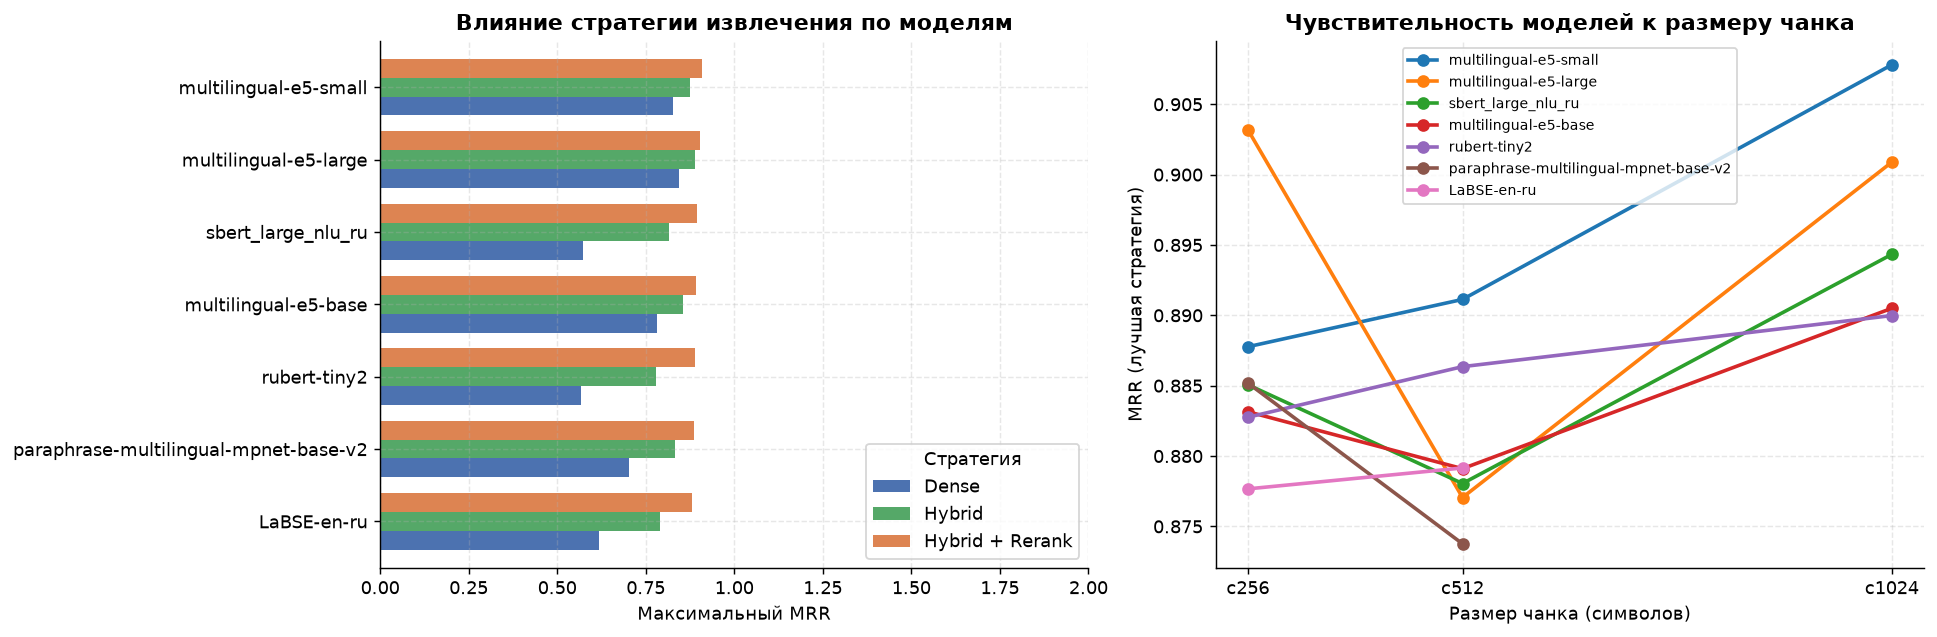

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, max(5, df["embedding"].nunique() * 0.5)))

# 4.1 Сравнение стратегий (при лучшем чанке для каждой модели)
piv_strat = (
    df.pivot_table(index="embedding", columns="strategy", values="mrr", aggfunc="max")
    .reindex(index=model_order[::-1])
)
avail_strats = [s for s in ["Dense", "Hybrid", "Hybrid + Rerank"] if s in piv_strat.columns]
piv_strat[avail_strats].plot.barh(
    ax=ax1, width=0.78, color=["#4C72B0", "#55A868", "#DD8452"][:len(avail_strats)]
)
ax1.set_xlim(0, 1.05)
ax1.set_xlabel("Максимальный MRR")
ax1.set_ylabel("")
ax1.set_title("Влияние стратегии извлечения по моделям", fontweight="bold")
ax1.legend(title="Стратегия", loc="lower right")

# 4.2 Чувствительность моделей к размеру чанка (Line Plot)
piv_chunk = df.pivot_table(index="chunk_size", columns="embedding", values="mrr", aggfunc="max")
for model_name in model_order[:8]:
    if model_name in piv_chunk.columns:
        series = piv_chunk[model_name].dropna()
        ax2.plot(series.index, series.values, marker="o", linewidth=2, label=model_name)

ax2.set_xticks(sorted(df["chunk_size"].unique()))
ax2.set_xticklabels([f"c{c}" for c in sorted(df["chunk_size"].unique())])
ax2.set_xlabel("Размер чанка (символов)")
ax2.set_ylabel("MRR (лучшая стратегия)")
ax2.set_title("Чувствительность моделей к размеру чанка", fontweight="bold")
ax2.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.show()

## 5. Фронт Парето: Качество (MRR) vs Скорость ответа (Latency)
Определяет оптимальные конфигурации, которые дают максимальный MRR при минимальном времени отклика.

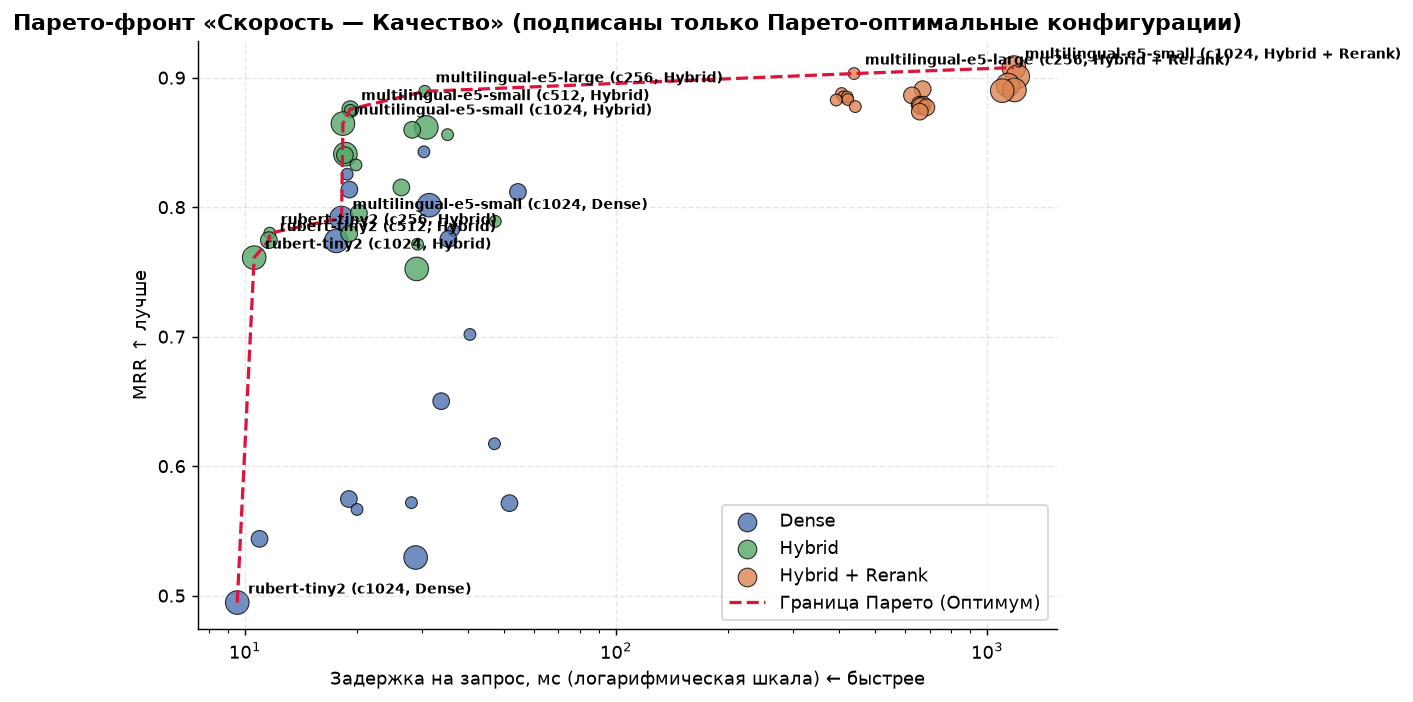

In [34]:
df_lat = df.dropna(subset=["ms_per_query", "mrr"]).copy()

if not df_lat.empty:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    strategy_colors = {"Dense": "#4C72B0", "Hybrid": "#55A868", "Hybrid + Rerank": "#DD8452"}

    for strat, grp in df_lat.groupby("strategy"):
        sizes = grp["chunk_size"] / 6.0
        ax.scatter(
            grp["ms_per_query"], grp["mrr"],
            s=sizes, label=strat, color=strategy_colors.get(strat, "steelblue"),
            alpha=0.8, edgecolors="black", linewidth=0.6
        )

    # Вычисление и отрисовка истинной границы Парето
    df_sorted_lat = df_lat.sort_values("ms_per_query")
    pareto_pts = []
    best_mrr_so_far = -1.0
    for _, r in df_sorted_lat.iterrows():
        if r["mrr"] > best_mrr_so_far:
            pareto_pts.append(r)
            best_mrr_so_far = r["mrr"]
    df_pareto = pd.DataFrame(pareto_pts)

    ax.plot(
        df_pareto["ms_per_query"], df_pareto["mrr"],
        color="crimson", linestyle="--", linewidth=1.8, label="Граница Парето (Оптимум)"
    )

    for _, r in df_pareto.iterrows():
        ax.annotate(
            f"{r['embedding']} (c{r['chunk_size']}, {r['strategy']})",
            (r["ms_per_query"], r["mrr"]),
            xytext=(6, 5), textcoords="offset points", fontsize=8, fontweight="bold"
        )

    ax.set_xscale("log")
    ax.set_xlabel("Задержка на запрос, мс (логарифмическая шкала) ← быстрее")
    ax.set_ylabel("MRR ↑ лучше")
    ax.set_title("Парето-фронт «Скорость — Качество» (подписаны только Парето-оптимальные конфигурации)", fontweight="bold")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

## 6. Кривые полноты Hit Rate @ K (Сравнение лидеров каждого семейства)

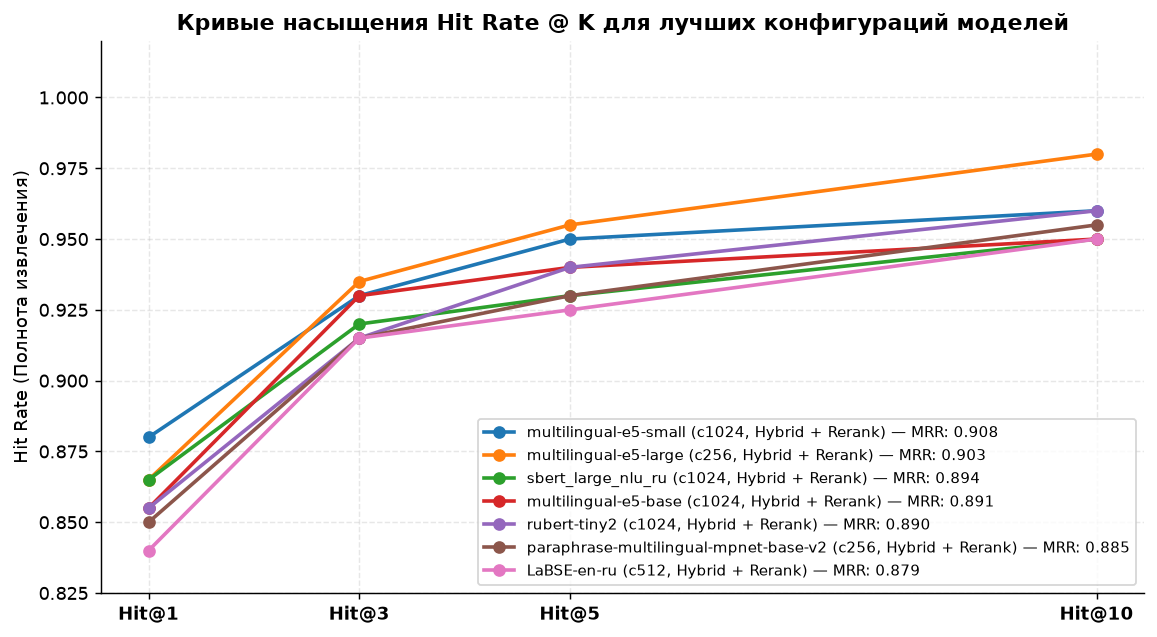

In [37]:
ks = [1, 3, 5, 10]
k_cols = ["hit@1", "hit@3", "hit@5", "hit@10"]
top_models = best_per_model.dropna(subset=["hit@10"]).head(8)

fig, ax = plt.subplots(figsize=(9, 5))
for _, row in top_models.iterrows():
    label = f"{row['embedding']} (c{row['chunk_size']}, {row['strategy']}) — MRR: {row['mrr']:.3f}"
    ax.plot(ks, [row[c] for c in k_cols], marker="o", linewidth=2, label=label)

ax.set_xticks(ks)
ax.set_xticklabels([f"Hit@{k}" for k in ks], fontweight="bold")
ax.set_ylim(0.825, 1.02)
ax.set_ylabel("Hit Rate (Полнота извлечения)")
ax.set_title("Кривые насыщения Hit Rate @ K для лучших конфигураций моделей", fontweight="bold")
ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout()
plt.show()